In [10]:
# # Install dependencies as needed:
# python -m pip install pandas matplotlib seaborn jupyter
# pip install kagglehub[pandas-datasets]
import pandas as pd
%matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import numpy as np
import requests
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import inspect
import json
from pathlib import Path
import streamlit as st
import joblib
from fastapi import FastAPI
from pydantic import BaseModel



Using matplotlib backend: module://matplotlib_inline.backend_inline


In [ ]:
path='/home/matthieumouillon/projects/app-streamlit/streamlit/Modèle/Data/Q_75_previous-1950-2024_RR-T-Vent.csv'
df = pd.read_csv(path, sep=';', decimal=',', encoding='utf-8-sig')

In [ ]:
df.shape

(496112, 60)

In [ ]:
details = (
    df.groupby("NOM_USUEL")
      .agg(
          nombre_de_postes=("NUM_POSTE", "nunique"),
          postes=("NUM_POSTE", lambda s: sorted(s.dropna().unique())),
      )
      .query("nombre_de_postes >= 1")
      .sort_values("nombre_de_postes", ascending=False)
)

display(details)

,nombre_de_postes,postes
NOM_USUEL,,
AUTEUIL,2,"[75116001, 75116005]"
BAGATELLE,1,[75116002]
BATIGNOLLES,1,[75117001]
BELLEVILLE,1,[75120004]
BELLEVILLE PARC,1,[75120006]
BUTTES CHAUMONT,1,[75119001]
BUTTES RESERV.,1,[75119004]
CHAMP DE MARS,1,[75107004]
CHARONNE,1,[75120001]


In [ ]:
serie = df.query("NOM_USUEL == 75116002")
print(serie.count())

NUM_POSTE       0
NOM_USUEL       0
LAT             0
LON             0
ALTI            0
AAAAMMJJ        0
RR              0
QRR             0
TN              0
QTN             0
HTN             0
QHTN            0
TX              0
QTX             0
HTX             0
QHTX            0
TM              0
QTM             0
TNTXM           0
QTNTXM          0
TAMPLI          0
QTAMPLI         0
TNSOL           0
QTNSOL          0
TN50            0
QTN50           0
DG              0
QDG             0
FFM             0
QFFM            0
FF2M            0
QFF2M           0
FXY             0
QFXY            0
DXY             0
QDXY            0
HXY             0
QHXY            0
FXI             0
QFXI            0
DXI             0
QDXI            0
HXI             0
QHXI            0
FXI2            0
QFXI2           0
DXI2            0
QDXI2           0
HXI2            0
QHXI2           0
FXI3S           0
QFXI3S          0
DXI3S           0
QDXI3S          0
HXI3S           0
QHXI3S    

In [ ]:
df.shape

(496112, 60)

In [ ]:
s = df[["NOM_USUEL", "AAAAMMJJ"]]

doublons = s.duplicated()
print("Nombre de lignes en doublon :", doublons.sum())

s[doublons]

Nombre de lignes en doublon : 4046


,NOM_USUEL,AAAAMMJJ
383833,AUTEUIL,19730101
383834,AUTEUIL,19730102
383835,AUTEUIL,19730103
383836,AUTEUIL,19730104
383837,AUTEUIL,19730105
...,...,...
387904,AUTEUIL,19840727
387905,AUTEUIL,19840728
387906,AUTEUIL,19840729
387907,AUTEUIL,19840730


In [ ]:
df['NOM_USUEL'].head(5)

0    INNOCENTS
1    INNOCENTS
2    INNOCENTS
3    INNOCENTS
4    INNOCENTS
Name: NOM_USUEL, dtype: str

In [ ]:
station_id = "PARIS-MONTSOURIS"   # Exemple : station de Montsouris

serie = df.loc[
    df["NOM_USUEL"] == station_id,
    ["AAAAMMJJ", "RR"],
].copy()

serie["ds"] = pd.to_datetime(
    serie["AAAAMMJJ"].astype(str),
    format="%Y%m%d"
)

serie = (
    serie.rename(columns={"RR": "y"})
    [["ds", "y"]]
    .dropna()
    .sort_values("ds")
    .reset_index(drop=True)
)

serie.head()

,ds,y
0,1950-01-01,0.0
1,1950-01-02,1.7
2,1950-01-03,2.4
3,1950-01-04,1.1
4,1950-01-05,2.0


In [ ]:
moyenne=serie['ds'].mean()
moyenne

NameError: name 'serie' is not defined

In [ ]:
X = serie["ds"]
y = serie["y"]

In [ ]:
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

In [ ]:
print("Cibles manquantes :", y.isna().sum())

Cibles manquantes : 0


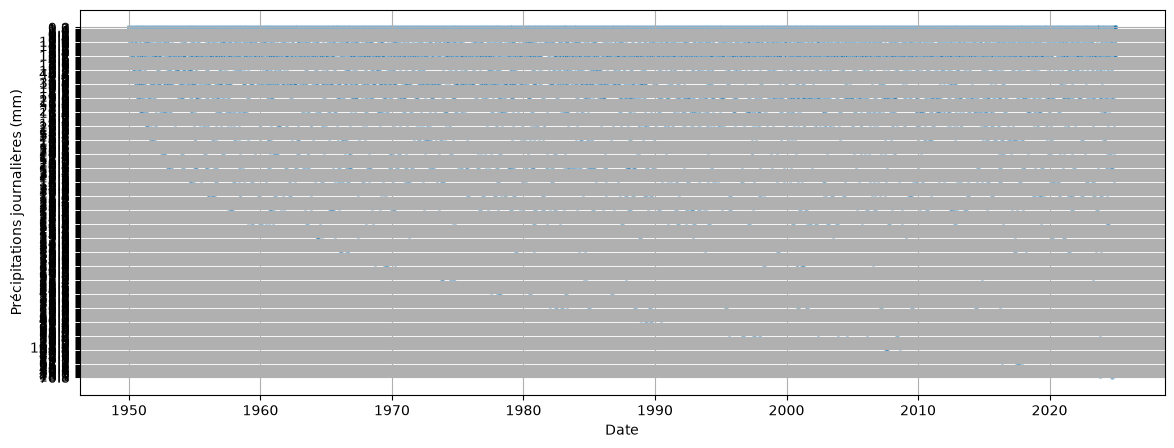

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

sns.scatterplot(
    data=serie,
    x="ds",
    y="y",
    alpha=0.5,
    s=12,
    ax=ax,
)

ax.set_xlabel("Date")
ax.set_ylabel("Précipitations journalières (mm)")
ax.grid(True)
plt.show()

In [ ]:
print(serie[["ds", "y"]].tail())
print("Observations :", len(serie))
print("Période :", serie["ds"].min(), "à", serie["ds"].max())
print("X :", type(X), "| y :", type(y))

              ds    y
27389 2024-12-27  0.0
27390 2024-12-28  0.0
27391 2024-12-29  0.0
27392 2024-12-30  0.0
27393 2024-12-31  0.0
Observations : 27394
Période : 1950-01-01 00:00:00 à 2024-12-31 00:00:00
X : <class 'pandas.Series'> | y : <class 'pandas.Series'>


          ds    y
0 1950-01-01  0.0
1 1950-01-02  1.7
2 1950-01-03  2.4
3 1950-01-04  1.1
4 1950-01-05  2.0
Nombre de lignes : 27394


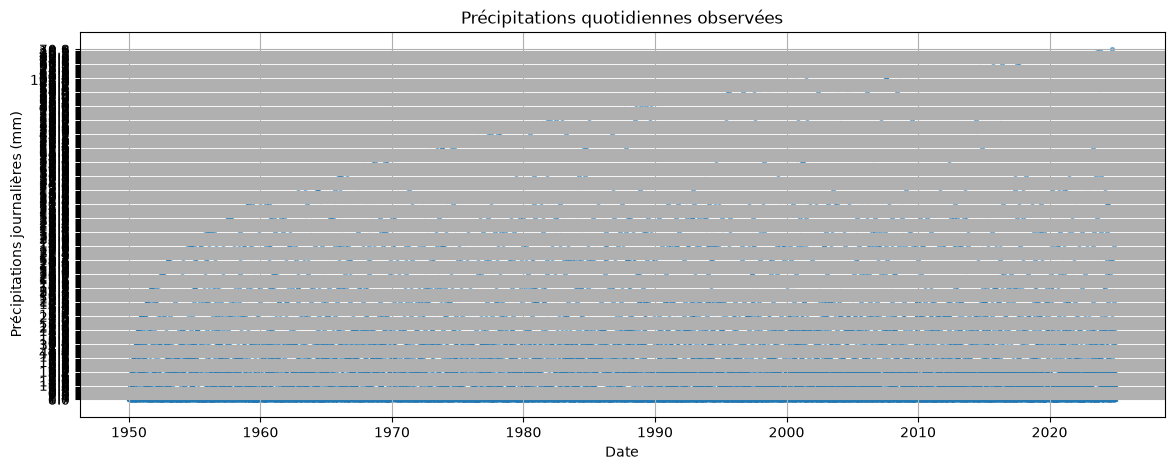

In [ ]:
import matplotlib.pyplot as plt

print(serie[["ds", "y"]].head())
print("Nombre de lignes :", len(serie))

plt.figure(figsize=(14, 5))
plt.scatter(serie["ds"], serie["y"], s=8, alpha=0.5)
plt.xlabel("Date")
plt.ylabel("Précipitations journalières (mm)")
plt.title("Précipitations quotidiennes observées")
plt.grid(True)
plt.show()

In [ ]:
from prophet import Prophet

model = Prophet()

Importing plotly failed. Interactive plots will not work.
/home/matthieumouillon/projects/app-streamlit/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
#python -m pip install prophet
import pandas as pd
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

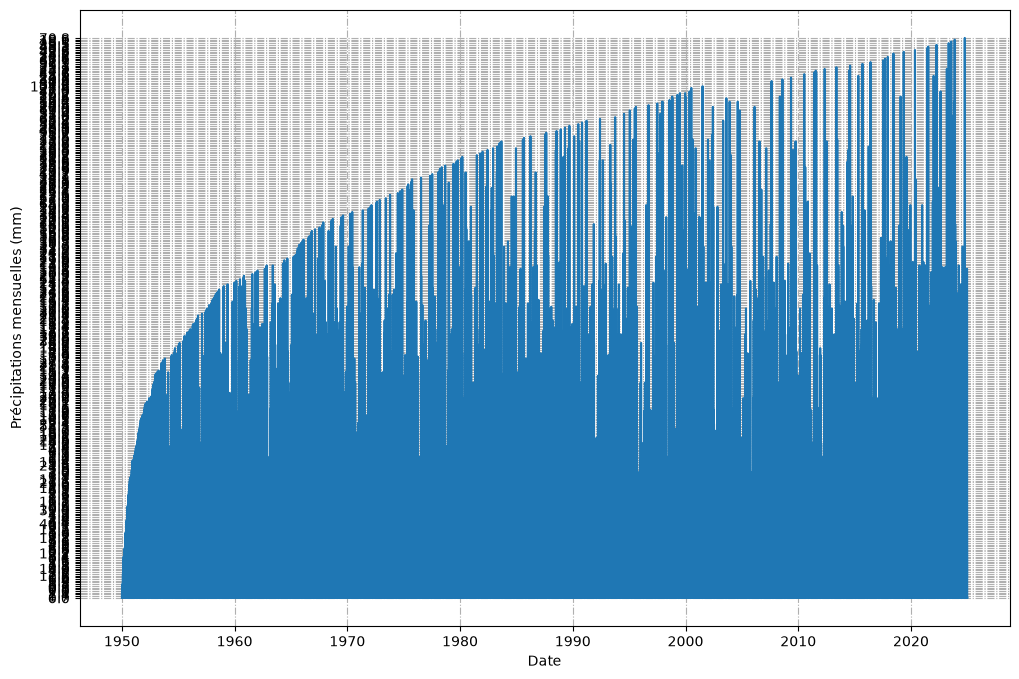

In [ ]:
plt.figure(figsize=(12, 8))
plt.grid(linestyle='-.')

plt.plot(serie["ds"], serie["y"])
plt.xlabel("Date")
plt.ylabel("Précipitations mensuelles (mm)")
plt.show()

In [ ]:
n_test = 81

train = serie.iloc[:-n_test].copy()
test = serie.iloc[-n_test:].copy()

print("Entraînement :", len(train))
print("Test :", len(test))
print("Fin de l'entraînement :", train["ds"].max())
print("Début du test :", test["ds"].min())

Entraînement : 27313
Test : 81
Fin de l'entraînement : 2024-10-11 00:00:00
Début du test : 2024-10-12 00:00:00


In [ ]:
print("--- Diagnostic des dates ---")
print("Type de la colonne ds :", serie['ds'].dtype)
print("Première date détectée :", serie['ds'].min())
print("Dernière date détectée :", serie['ds'].max())
print("Nombre total de lignes :", len(serie))
print("----------------------------")


--- Diagnostic des dates ---
Type de la colonne ds : datetime64[us]
Première date détectée : 1950-01-01 00:00:00
Dernière date détectée : 2024-12-31 00:00:00
Nombre total de lignes : 27394
----------------------------


In [ ]:
model = Prophet(seasonality_mode='multiplicative', interval_width=0.95)
model.fit(train)

13:39:31 - cmdstanpy - INFO - Chain [1] start processing
13:39:36 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
horizon = 36  # prévoir les 36 mois qui suivent la dernière date d'entraînement

future = model.make_future_dataframe(
    periods=horizon,
    freq="MS",
)

forecast = model.predict(future)

forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(36)

,ds,yhat,yhat_lower,yhat_upper
27313,2024-11-01,2.347832,-5.546438,10.816667
27314,2024-12-01,1.968280,-6.070698,9.646754
27315,2025-01-01,2.198154,-5.607199,9.900006
27316,2025-02-01,1.988142,-6.726943,11.126316
27317,2025-03-01,1.485678,-6.478002,9.071324
27318,2025-04-01,1.850827,-5.869373,10.301203
27319,2025-05-01,2.096337,-5.696553,10.042094
27320,2025-06-01,2.575038,-5.162250,10.556203
27321,2025-07-01,2.289112,-6.034413,10.476798
27322,2025-08-01,2.064077,-6.473778,9.787185


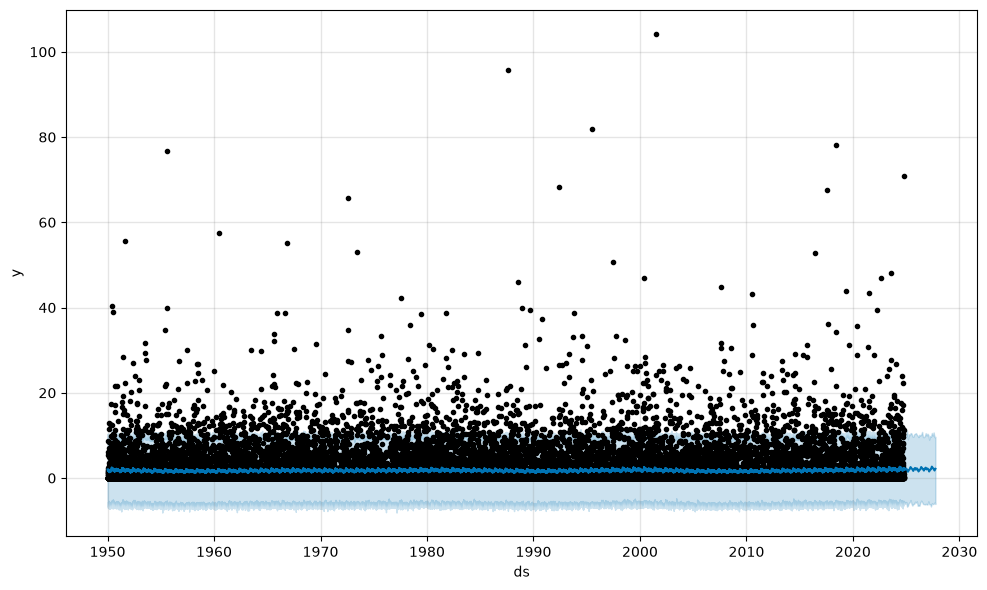

In [ ]:
ax = model.plot(forecast);

In [ ]:
cv_results = cross_validation(model=model, initial=f'{365 * 3} days', horizon='365 days', period='180 days')
cv_results

  0%|          | 0/144 [00:00<?, ?it/s]13:40:13 - cmdstanpy - INFO - Chain [1] start processing
13:40:13 - cmdstanpy - INFO - Chain [1] done processing
  1%|          | 1/144 [00:00<01:15,  1.89it/s]13:40:14 - cmdstanpy - INFO - Chain [1] start processing
13:40:14 - cmdstanpy - INFO - Chain [1] done processing
  1%|▏         | 2/144 [00:00<01:02,  2.25it/s]13:40:14 - cmdstanpy - INFO - Chain [1] start processing
13:40:14 - cmdstanpy - INFO - Chain [1] done processing
  2%|▏         | 3/144 [00:01<01:05,  2.15it/s]13:40:15 - cmdstanpy - INFO - Chain [1] start processing
13:40:15 - cmdstanpy - INFO - Chain [1] done processing
  3%|▎         | 4/144 [00:01<01:00,  2.33it/s]13:40:15 - cmdstanpy - INFO - Chain [1] start processing
13:40:15 - cmdstanpy - INFO - Chain [1] done processing
  3%|▎         | 5/144 [00:02<01:00,  2.28it/s]13:40:16 - cmdstanpy - INFO - Chain [1] start processing
13:40:16 - cmdstanpy - INFO - Chain [1] done processing
  4%|▍         | 6/144 [00:02<01:03,  2.16it/s]1

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,1953-04-23,1.767112,-5.748789,9.272525,0.0,1953-04-22
1,1953-04-24,1.550985,-6.509239,9.446312,0.0,1953-04-22
2,1953-04-25,1.175519,-6.633154,8.985759,0.0,1953-04-22
3,1953-04-26,1.246482,-7.311820,8.929477,7.7,1953-04-22
4,1953-04-27,0.965394,-6.366683,8.563423,0.2,1953-04-22
...,...,...,...,...,...,...
52555,2024-10-07,1.686747,-5.991255,9.719311,11.3,2023-10-12
52556,2024-10-08,1.716039,-6.179948,9.751035,1.8,2023-10-12
52557,2024-10-09,1.671776,-5.731432,9.547652,70.8,2023-10-12
52558,2024-10-10,1.730046,-5.990866,9.573968,2.0,2023-10-12


In [ ]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mdape,smape,coverage
0,37 days,18.576743,4.310075,2.439376,inf,1.528626,0.947489
1,38 days,18.903919,4.347864,2.447708,inf,1.529309,0.947108
2,39 days,19.272906,4.390092,2.461705,inf,1.528160,0.945871
3,40 days,19.164800,4.377762,2.460381,inf,1.527890,0.945586
4,41 days,18.848662,4.341505,2.448039,inf,1.525393,0.946537
...,...,...,...,...,...,...,...
324,361 days,15.860699,3.982549,2.292511,inf,1.526882,0.958333
325,362 days,15.533338,3.941236,2.284234,inf,1.524878,0.958619
326,363 days,15.515964,3.939031,2.293300,inf,1.525526,0.957287
327,364 days,14.703550,3.834521,2.278925,inf,1.524947,0.957763


In [ ]:
df_p = performance_metrics(cv_results)
df_p

,horizon,mse,rmse,mae,mdape,smape,coverage
0,37 days,18.576743,4.310075,2.439376,inf,1.528626,0.947489
1,38 days,18.903919,4.347864,2.447708,inf,1.529309,0.947108
2,39 days,19.272906,4.390092,2.461705,inf,1.528160,0.945871
3,40 days,19.164800,4.377762,2.460381,inf,1.527890,0.945586
4,41 days,18.848662,4.341505,2.448039,inf,1.525393,0.946537
...,...,...,...,...,...,...,...
324,361 days,15.860699,3.982549,2.292511,inf,1.526882,0.958333
325,362 days,15.533338,3.941236,2.284234,inf,1.524878,0.958619
326,363 days,15.515964,3.939031,2.293300,inf,1.525526,0.957287
327,364 days,14.703550,3.834521,2.278925,inf,1.524947,0.957763


In [ ]:
from prophet.plot import plot_cross_validation_metric


In [ ]:
forecast_test = model.predict(test[["ds"]])

resultats = test.merge(
    forecast_test[["ds", "yhat"]],
    on="ds",
)

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

mse = mean_squared_error(resultats["y"], resultats["yhat"])
rmse = np.sqrt(mse)
mae = mean_absolute_error(resultats["y"], resultats["yhat"])

print(f"MSE  : {mse:.2f} mm²")
print(f"RMSE : {rmse:.2f} mm")
print(f"MAE  : {mae:.2f} mm")

MSE  : 18.14 mm²
RMSE : 4.26 mm
MAE  : 2.75 mm


In [ ]:
display(resultats[["ds", "y", "yhat"]].tail(10))

,ds,y,yhat
71,2024-12-22,8.5,2.264277
72,2024-12-23,1.2,2.235628
73,2024-12-24,0.6,2.279954
74,2024-12-25,0.2,2.274102
75,2024-12-26,0.0,2.319309
76,2024-12-27,0.0,2.234124
77,2024-12-28,0.0,2.207456
78,2024-12-29,0.0,2.229185
79,2024-12-30,0.0,2.186918
80,2024-12-31,0.0,2.217588


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

prediction_zero = np.zeros(len(resultats))

print("MAE référence zéro :", mean_absolute_error(resultats["y"], prediction_zero))
print("RMSE référence zéro :", np.sqrt(mean_squared_error(resultats["y"], prediction_zero)))

MAE référence zéro : 1.8592592592592596
RMSE référence zéro : 4.616743547962603


In [ ]:
print("Part des jours sans pluie :", (resultats["y"] == 0).mean())


Part des jours sans pluie : 0.0


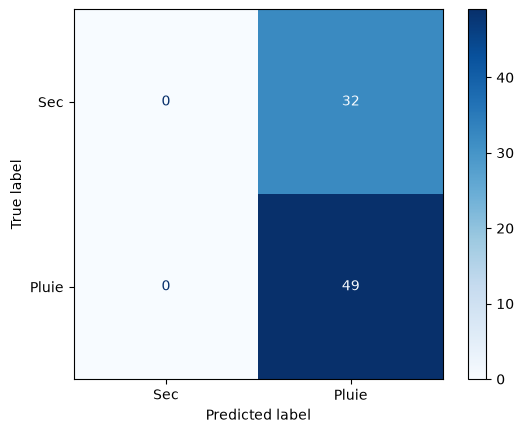

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Observations réelles et prédictions transformées en catégories
pluie_observee = resultats["y"] > 0
pluie_predite = resultats["yhat"] > 0

cm = confusion_matrix(
    pluie_observee,
    pluie_predite,
    labels=[False, True],
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sec", "Pluie"],
)

affichage.plot(cmap="Blues", values_format="d")
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

precision = precision_score(
    pluie_observee, pluie_predite, zero_division=0
)
recall = recall_score(
    pluie_observee, pluie_predite, zero_division=0
)
f1 = f1_score(
    pluie_observee, pluie_predite, zero_division=0
)
accuracy = accuracy_score(pluie_observee, pluie_predite)

print(f"Précision (Precision) : {precision:.3f} ({precision:.1%})")
print(f"Rappel (Recall)       : {recall:.3f} ({recall:.1%})")
print(f"F1-score              : {f1:.3f} ({f1:.1%})")
print(f"Accuracy              : {accuracy:.3f} ({accuracy:.1%})")

Précision (Precision) : 0.605 (60.5%)
Rappel (Recall)       : 1.000 (100.0%)
F1-score              : 0.754 (75.4%)
Accuracy              : 0.605 (60.5%)


In [ ]:
import pandas as pd
from prophet import Prophet

# Pour la prévision finale, utilise toutes les observations disponibles
model = Prophet()
model.fit(serie[["ds", "y"]])

aujourd_hui = pd.Timestamp.today().normalize()
date_cible = aujourd_hui + pd.DateOffset(years=1)

derniere_observation = serie["ds"].max()
horizon_jours = (date_cible - derniere_observation).days

future = model.make_future_dataframe(
    periods=horizon_jours,
    freq="D",
)

forecast = model.predict(future)

# Afficher les prévisions entre aujourd'hui et un an après
previsions_a_venir = forecast.loc[
    forecast["ds"].between(aujourd_hui, date_cible),
    ["ds", "yhat", "yhat_lower", "yhat_upper"],
]

display(previsions_a_venir.head())
display(previsions_a_venir.tail())

09:55:32 - cmdstanpy - INFO - Chain [1] start processing
09:55:40 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
28046,2026-10-15,2.095056,-2.934557,7.223688
28047,2026-10-16,2.037508,-3.239719,7.323111
28048,2026-10-17,2.043941,-3.406486,7.270316
28049,2026-10-18,2.095707,-3.520132,7.345868
28050,2026-10-19,2.099823,-3.520152,7.499241


,ds,yhat,yhat_lower,yhat_upper
28407,2027-10-11,2.007899,-3.374226,7.279559
28408,2027-10-12,2.044795,-3.190629,7.344112
28409,2027-10-13,2.047257,-3.055627,7.159505
28410,2027-10-14,2.108145,-3.558361,7.131083
28411,2027-10-15,2.046533,-3.485423,7.422839


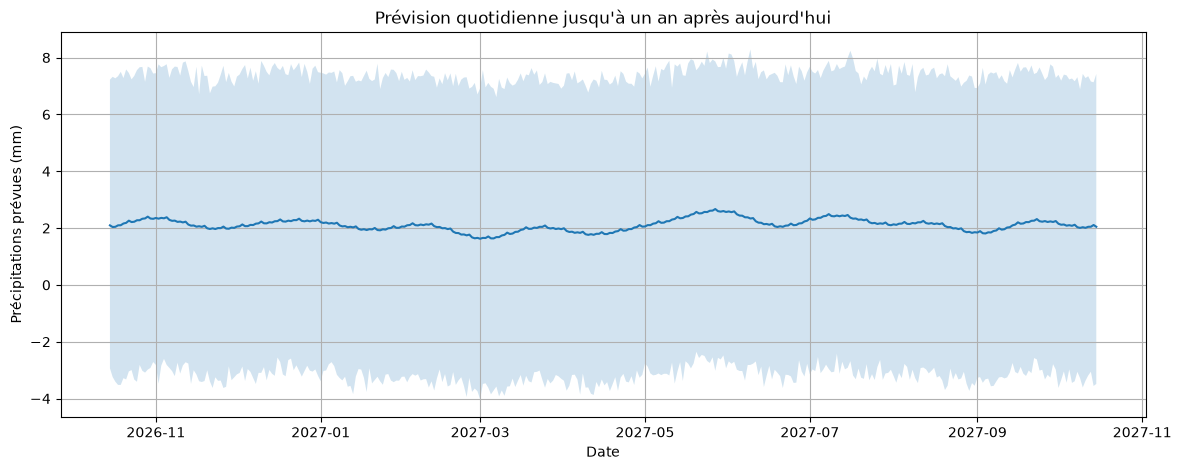

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(previsions_a_venir["ds"], previsions_a_venir["yhat"])
plt.fill_between(
    previsions_a_venir["ds"],
    previsions_a_venir["yhat_lower"],
    previsions_a_venir["yhat_upper"],
    alpha=0.2,
)
plt.xlabel("Date")
plt.ylabel("Précipitations prévues (mm)")
plt.title("Prévision quotidienne jusqu'à un an après aujourd'hui")
plt.grid(True)
plt.show()

In [ ]:
station_id = 'PARIS-MONTSOURIS'  # remplace par le poste choisi

new_datapoint = pd.DataFrame({
    "NOM_USUEL": [station_id],
    "ds": [pd.Timestamp("2027-06-17")],
})

prediction = model.predict(new_datapoint)

prediction.insert(0, "NOM_USUEL", station_id)
display(prediction[["NOM_USUEL", "ds", "yhat", "yhat_lower", "yhat_upper"]])

,NOM_USUEL,ds,yhat,yhat_lower,yhat_upper
0,PARIS-MONTSOURIS,2027-06-17,2.147155,-6.170063,10.914971


In [ ]:
import builtins

pluie_estimee = prediction["yhat"].iloc[0]
date_prevue = prediction["ds"].iloc[0]

builtins.print(
    f"Pour le {date_prevue:%d/%m/%Y}, la pluie estimée est "
    f"{pluie_estimee:.2f} mm."
)

Pour le 17/06/2027, la pluie estimée est 2.15 mm.


In [ ]:
import joblib
#Sauvegarde le modèle dans un fichier .joblib
#Chargé localement dans Model_manual.py
#Pas besoin de serveur
#Fast(API)Expose le modèle via HTTP ;Appelé à distance depuis Model_manual.py, Nécessite un serveur (Docker)

In [ ]:
import joblib

joblib.dump(
    {
        "preprocessor": future,
        "model": model,
        "moyenne": moyenne,
    },
    "weather_artifacts.joblib",
)

NameError: name 'future' is not defined

In [ ]:
artifacts = joblib.load("weather_artifacts.joblib")

future = artifacts["preprocessor"]
model = artifacts["model"]

In [ ]:
csv_path2 = '/home/matthieumouillon/projects/app-streamlit/streamlit/Modèle/Data/Q_75_latest-2025-2026_RR-T-Vent.csv'
df2 = pd.read_csv(csv_path2, sep=";", encoding="utf-8-sig")

FileNotFoundError: [Errno 2] No such file or directory: '/home/matthieumouillon/projects/app-streamlit/streamlit/Modèle/Data/Q_75_latest-2025-2026_RR-T-Vent.csv'

In [ ]:
df2.head(1)

,NUM_POSTE,NOM_USUEL,LAT,LON,ALTI,AAAAMMJJ,RR,QRR,TN,QTN,...,FXI3S,QFXI3S,DXI3S,QDXI3S,HXI3S,QHXI3S,DRR,QDRR,STATUS_FXI3S,STATUS_DXI3S
0,75106001,LUXEMBOURG,48.844833,2.3385,50,20250101,13.3,1.0,4.6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


: 

In [ ]:
print ('test')


test


In [ ]:
# from sklearn.model_selection import train_test_split
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.metrics import accuracy_score

# # X contains the input features; y contains the labels
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# model = RandomForestClassifier(n_estimators=100, random_state=42)
# model.fit(X_train, y_train)        # Learn from the training data

# predictions = model.predict(X_test)
# print("Accuracy:", accuracy_score(y_test, predictions))

In [ ]:
# model = RandomForestClassifier(n_estimators=___)
# model.___(X_train, y_train)
# predictions = model.___(X_test)

Notebook → joblib.dump() → weather_artifacts.joblib
↓
main.py (FastAPI + Pydantic)
↓
Docker (build/run) → Serveur sur localhost:8080
↓
Model_manual.py → httpx.post() → Appel API
